# LUMA Lokalny Urok Mistrzostwa Artystycznego

LUMA to lokalny jarmark który rośnie z tygodnia na tydzień, coraz więcej wystawców, więcej gości miejscowych i turystów, okazjonalnie promocje i sezonowość.

## Import Bibliotek

In [48]:
import numpy as np
import pandas as pd
from itertools import chain
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

## Wygenerowanie syntetycznych danych

## Ustawienia ziarna RNG

In [2]:
RNG_SEED = 20261020
rng = np.random.default_rng(RNG_SEED)
print('Ustawione ziarno RNG:', RNG_SEED)

Ustawione ziarno RNG: 20261020


## Zdefiniowanie "stałych"

In [3]:
LUMA_FULL = 'Lokalny Urok Mistrzostwa Artystycznego'
CATEGORIES = ['Ceramika','Tekstylia', 'Biżuteria', 'Rękodzieło', 'Przetwory', 'Dekoracje', 'Stolarka', 'Masarstwo', 'Alkohole']

## Przygotowanie bazowych danych syntetycznych

"Katalog" kategorii i ich bazowe parametry generatywne (syntetyczne)

In [4]:
catalog = pd.DataFrame({
    'category': CATEGORIES,
    'demand_loc_base': [120,180,130,80,160,150,70,90,110], #średni popyt lokalny (szt./tydz)
    'demand_tur_base': [60,40,80,30,90,30,50,40,80], # średni popyt turystyczny (szt./tydz)
    'price_pln_base': [8,120,150,230,40,35,250,215,135], #średnia cena jednostkowa (PLN/szt.)
})

Wyliczony "typowy" przychód tygodniowy (lokalni + turysci) * cena

In [5]:
catalog["revenue_avg_pln"] = (catalog["demand_loc_base"] + catalog["demand_tur_base"]) * catalog["price_pln_base"]

In [6]:
catalog

,category,demand_loc_base,demand_tur_base,price_pln_base,revenue_avg_pln
0,Ceramika,120,60,8,1440
1,Tekstylia,180,40,120,26400
2,Biżuteria,130,80,150,31500
3,Rękodzieło,80,30,230,25300
4,Przetwory,160,90,40,10000
5,Dekoracje,150,30,35,6300
6,Stolarka,70,50,250,30000
7,Masarstwo,90,40,215,27950
8,Alkohole,110,80,135,25650


## Przygotowanie funckji pomocniczych do generowania danych tygodniowych

Generowanie popytu lokalnego i turystycznego na podstawie danych bazowych, z losowym szumem (multiplikatywnym) i opcjonalnymi boostami (%)

In [7]:
def determine_demand(catalog, rng, variance=0.15, boost_loc=0.0, boost_tur=0.0):
    df = catalog[["category", "demand_loc_base", "demand_tur_base"]].copy()
    eps_loc = np.clip(rng.normal(loc=1.0, scale=variance, size=len(df)), 0.5, 1.8)
    eps_tur = np.clip(rng.normal(loc=1.0, scale=variance, size=len(df)), 0.5, 1.8)
    df["demand_loc"] = (df["demand_loc_base"] * (1 + boost_loc)) * eps_loc
    df["demand_tur"] = (df["demand_tur_base"] * (1 + boost_tur)) * eps_tur 
    df["demand_loc"] = np.maximum(df["demand_loc"].round().astype(int), 0)
    df["demand_tur"] = np.maximum(df["demand_tur"].round().astype(int), 0)
    return df[["category", "demand_loc", "demand_tur"]]

Wyliczanie przychodu lokalnego, turystycznego i łącznego

In [8]:
def count_revenue(catalog, demand_df):
    df = demand_df.merge(catalog[["category", "price_pln_base"]], on="category", how="left")
    df["revenue_loc"] = df["demand_loc"] * df["price_pln_base"]
    df["revenue_tur"] = df["demand_tur"] * df["price_pln_base"]
    df["revenue_pln"] = df["revenue_loc"] + df["revenue_tur"]
    return df[["category", "revenue_loc", "revenue_tur", "revenue_pln"]]

Generowanie danych tygodniowych

In [9]:
def generate_weekly_data(catalog, rng, variance=0.15, boost_loc=0.0, boost_tur=0.0):
    demand_df = determine_demand(catalog, rng, variance=variance, boost_loc=boost_loc, boost_tur=boost_tur)
    revenue_df = count_revenue(catalog, demand_df)
    return revenue_df

## Wygenerowanie danych tygoniowych dla Tygodnia 1

In [10]:
t1 = generate_weekly_data(catalog, rng)
t1 = t1.merge(catalog[["category", "price_pln_base"]], on="category", how="left")
print("Tydzień 1 - przychody per kategoria (PLN)")
display(t1)
print("Łączny przychód w tygodniu 1 (PLN): ", t1["revenue_pln"].sum())

Tydzień 1 - przychody per kategoria (PLN)


,category,revenue_loc,revenue_tur,revenue_pln,price_pln_base
0,Ceramika,688,392,1080,8
1,Tekstylia,21240,3360,24600,120
2,Biżuteria,13350,11700,25050,150
3,Rękodzieło,22540,6440,28980,230
4,Przetwory,7720,3680,11400,40
5,Dekoracje,4900,1120,6020,35
6,Stolarka,19000,14250,33250,250
7,Masarstwo,18275,8815,27090,215
8,Alkohole,18630,10260,28890,135


Łączny przychód w tygodniu 1 (PLN):  186360


## Analiza i wizualizacja danych - 1 seria danych

Podstawowe wykresy

<Axes: >

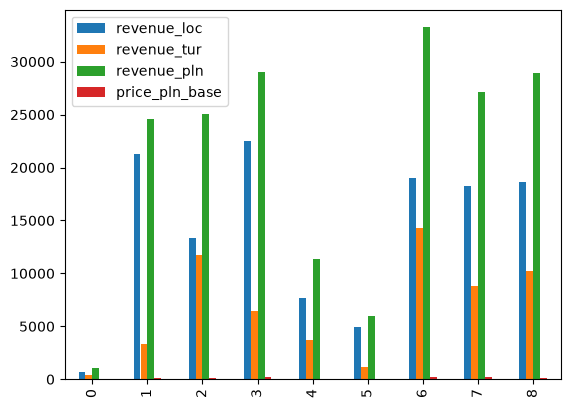

In [11]:
t1.plot.bar()

<Axes: >

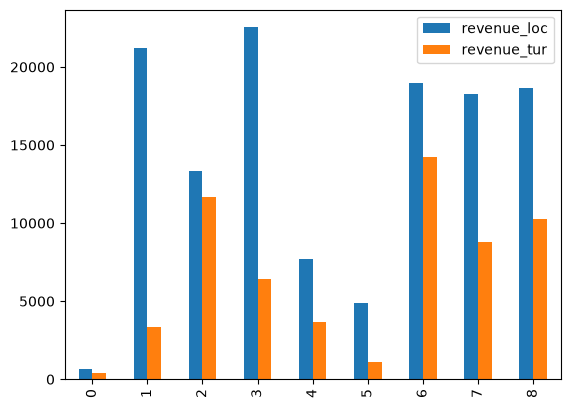

In [12]:
t1[["revenue_loc", "revenue_tur"]].plot.bar()

<Axes: >

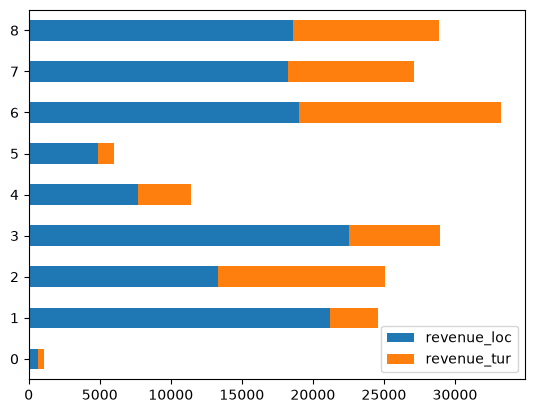

In [13]:
t1[["revenue_loc", "revenue_tur"]].plot.barh(stacked=True)

Minimalny wykres

<BarContainer object of 9 artists>

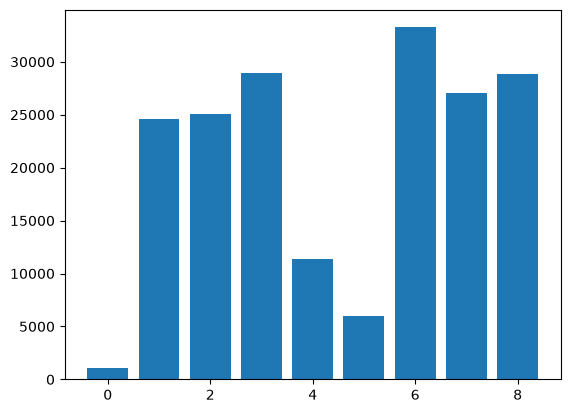

In [14]:
heights = t1["revenue_pln"]
plt.bar(range(len(heights)), heights)

Jawne tworzenie i wyświetlanie wykresu

In [15]:
heights = t1["revenue_pln"]
categories = t1["category"]

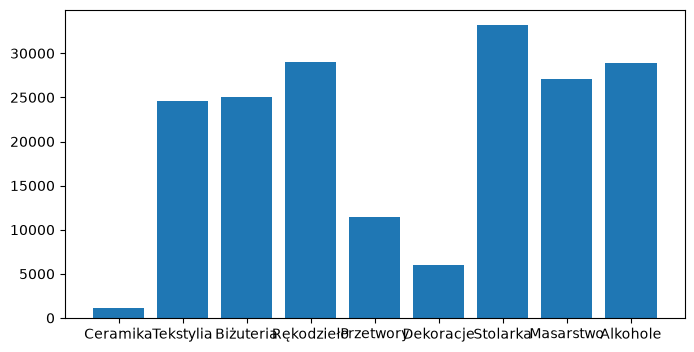

In [16]:
plt.figure(figsize=(8, 4))
plt.bar(categories, heights)
plt.show()

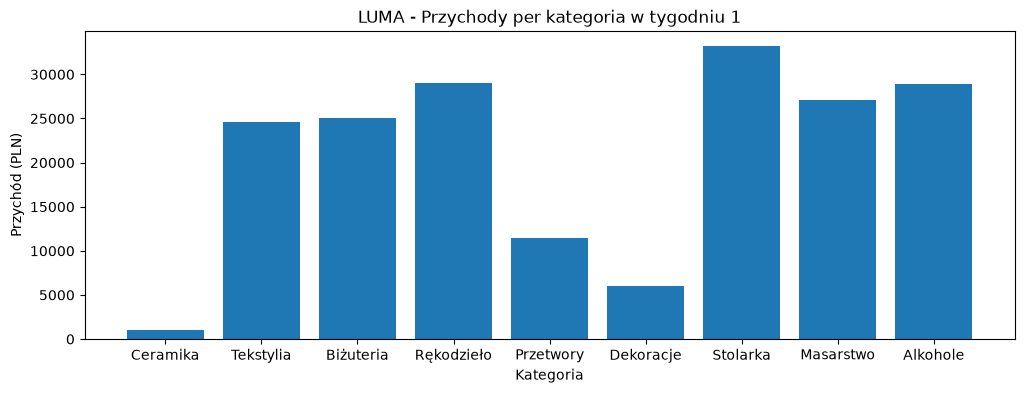

In [17]:
plt.figure(figsize=(12, 4))
plt.bar(categories, heights)
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.show()

Etykiety wartości i formatowanie liczb

In [18]:
def format_pln(x: float) -> str:
    return f"{int(round(x)):,} zł".replace(",", "\u202f")

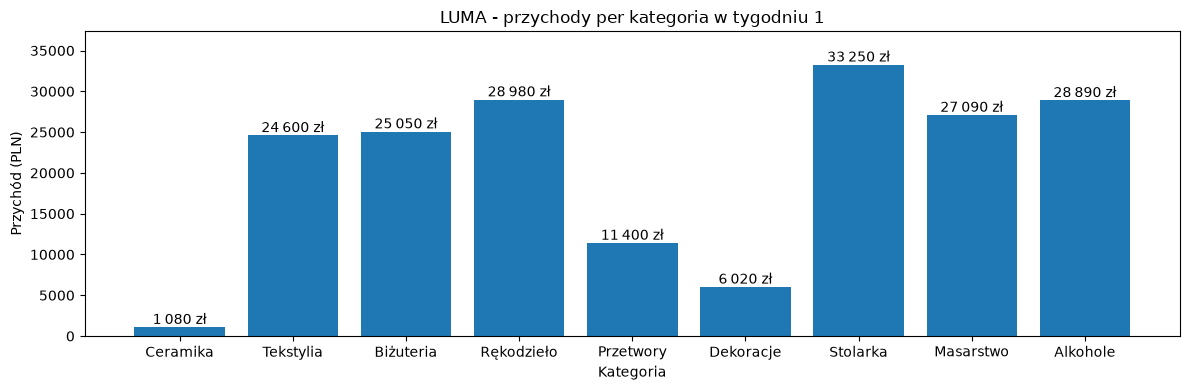

In [19]:
plt.figure(figsize=(12, 4))
bars = plt.bar(categories, heights)
ymin, ymax = plt.ylim() # pobranie min, max dla y
pad = (ymax - ymin) * 0.07
plt.ylim(ymin, ymax + pad) # nowa wartość y max
for bar in bars:
    x = bar.get_x() + bar.get_width() / 2
    y = bar.get_height()
    plt.text(x, y, format_pln(y), ha="center", va="bottom")
plt.title("LUMA - przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.tight_layout()
plt.show()

In [20]:
def pad_axis(factor=0.07):
    ymin, ymax = plt.ylim() # pobranie min, max dla y
    pad = (ymax - ymin) * factor
    plt.ylim(ymin, ymax + pad) # nowa wartość y max

In [21]:
def label_bars_pln(bars):
    for bar in bars:
        x = bar.get_x() + bar.get_width() / 2
        y = bar.get_height()
        plt.text(x, y, format_pln(y), ha="center", va="bottom")

Formatowanie etykiet podziałki osi

In [22]:
def format_tys(x: float, decimals: int = 0) -> str:
    v = x / 1000.0
    if decimals == 0:
        s = f"{int(round(v)):,}".replace(",", "\u202f")
    else:
        s = f"{v:,.{decimals}f}".replace(",", "\u202f").replace(".", ",")
    return s + " tys."

In [23]:
def format_mln(x: float, decimals: int = 0) -> str:
    v = x / 1000000.0
    if decimals == 0:
        s = f"{int(round(v)):,}".replace(",", "\u202f")
    else:
        s = f"{v:,.{decimals}f}".replace(",", "\u202f").replace(".", ",")
    return s + " mln."

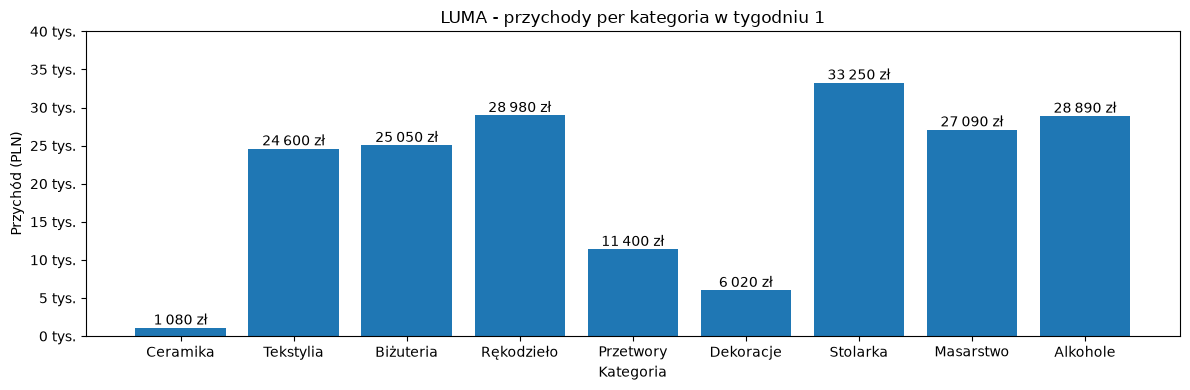

In [24]:
plt.figure(figsize=(12, 4))
bars = plt.bar(categories, heights)
pad_axis()
label_bars_pln(bars)
ypos, ylab_old = plt.yticks()
ylab_new = [format_tys(y) for y in ypos]
plt.yticks(ypos, ylab_new)
plt.title("LUMA - przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.tight_layout()
plt.show()

In [25]:
def format_ytics_tys():
    ypos, _ = plt.yticks()
    ylab_new = [format_tys(y) for y in ypos]
    plt.yticks(ypos, ylab_new)

Sortowanie kategorii dla łatwiejszego porównania

In [26]:
t1_sorted = t1.sort_values("revenue_pln", ascending=False).reset_index()
categories = t1_sorted["category"]
heights = t1_sorted["revenue_pln"]

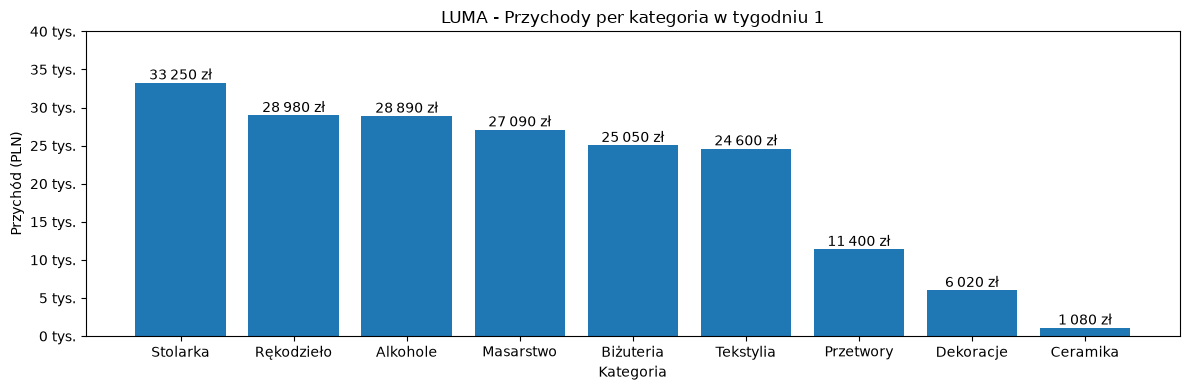

In [27]:
plt.figure(figsize=(12, 4))
bars = plt.bar(categories, heights)
pad_axis()
label_bars_pln(bars)
format_ytics_tys()
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.tight_layout()
plt.show()

Siatka w tle wykresu

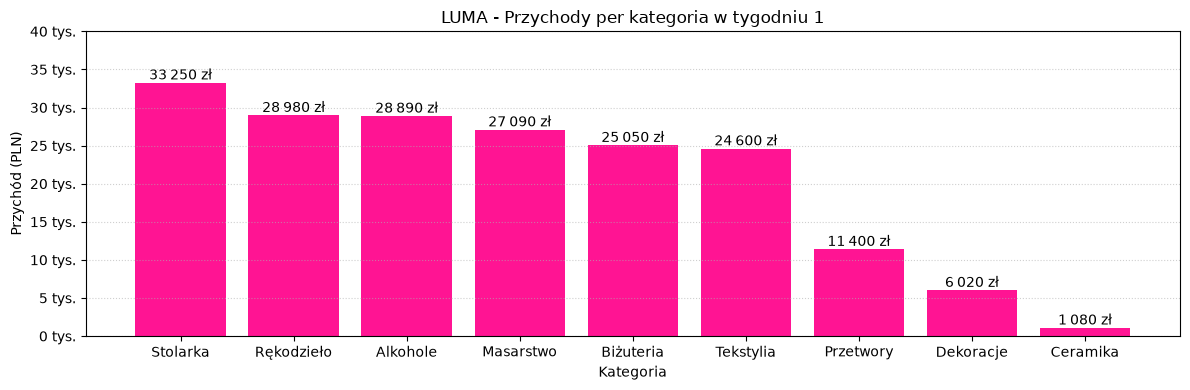

In [28]:
plt.figure(figsize=(12, 4))
bars = plt.bar(categories, heights, color="deeppink")
pad_axis()
label_bars_pln(bars)
format_ytics_tys()
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.tight_layout()
plt.show()

## Analiza i wizualizacja danych - 2 serie danych

### Wygenerowanie danych tygodniowych dla tygodnia 2
Mini-festiwal przyciąga klientów: lokalni + 13%, turyści +20%

In [29]:
boost_loc = 0.13
boost_tur = 0.20

t2 = generate_weekly_data(catalog, rng, boost_loc=boost_loc, boost_tur=boost_tur)
t2 = t2.merge(catalog[["category", "price_pln_base"]], on="category", how="left")
print("Tydzień 2 - przychody per kategoria (PLN)")
display(t2)
print("Łączny przychód w tygodniu 1: ", format_pln(t1["revenue_pln"].sum()))
print("Łączny przychód w tygodniu 2: ", format_pln(t2["revenue_pln"].sum()))

Tydzień 2 - przychody per kategoria (PLN)


,category,revenue_loc,revenue_tur,revenue_pln,price_pln_base
0,Ceramika,1160,720,1880,8
1,Tekstylia,27720,4920,32640,120
2,Biżuteria,15000,13200,28200,150
3,Rękodzieło,15410,7590,23000,230
4,Przetwory,6440,5400,11840,40
5,Dekoracje,6090,1155,7245,35
6,Stolarka,20500,18000,38500,250
7,Masarstwo,20855,9030,29885,215
8,Alkohole,16875,19440,36315,135


Łączny przychód w tygodniu 1:  186 360 zł
Łączny przychód w tygodniu 2:  209 505 zł


Przygotowanie danych do wykresów

In [30]:
categories = t1_sorted["category"]
t1_revenue_total = t1_sorted["revenue_pln"]
t2_revenue_total = t2.set_index("category").loc[categories]["revenue_pln"]
x_locs = np.arange(len(categories))
bar_width = 0.4
bar_half = bar_width / 2

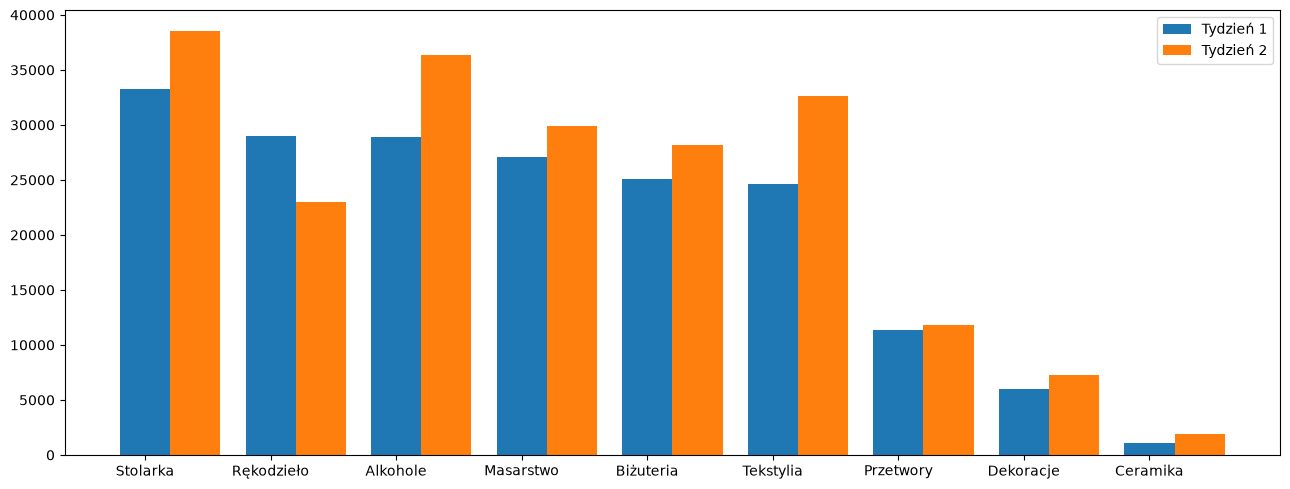

In [31]:
plt.figure(figsize=(13,5))
plt.bar(x_locs-bar_half, t1_revenue_total, width=bar_width, 
        label="Tydzień 1", tick_label=categories)
plt.bar(x_locs+bar_half, t2_revenue_total, width=bar_width, 
        label="Tydzień 2")
plt.legend()
plt.tight_layout()
plt.show()

Łączne operowanie na seriach

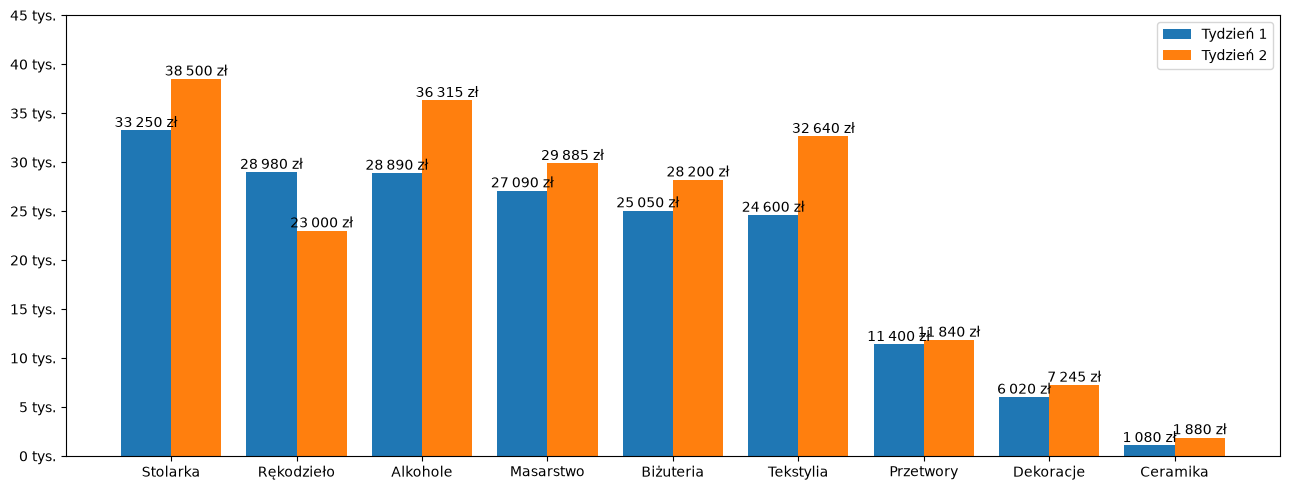

In [32]:
plt.figure(figsize=(13,5))
bars_1 = plt.bar(x_locs-bar_half, t1_revenue_total, width=bar_width, label="Tydzień 1")
bars_2 = plt.bar(x_locs+bar_half, t2_revenue_total, width=bar_width, label="Tydzień 2")
plt.xticks(x_locs, categories)
pad_axis()
label_bars_pln(chain(bars_1, bars_2))
format_ytics_tys()

plt.legend()
plt.tight_layout()
plt.show()

Aktualizacja wyświetlania etykiet wartości

In [33]:
def format_sep(x: float) -> str:
    return f"{int(round(x)):,}".replace(",", "\u202f")

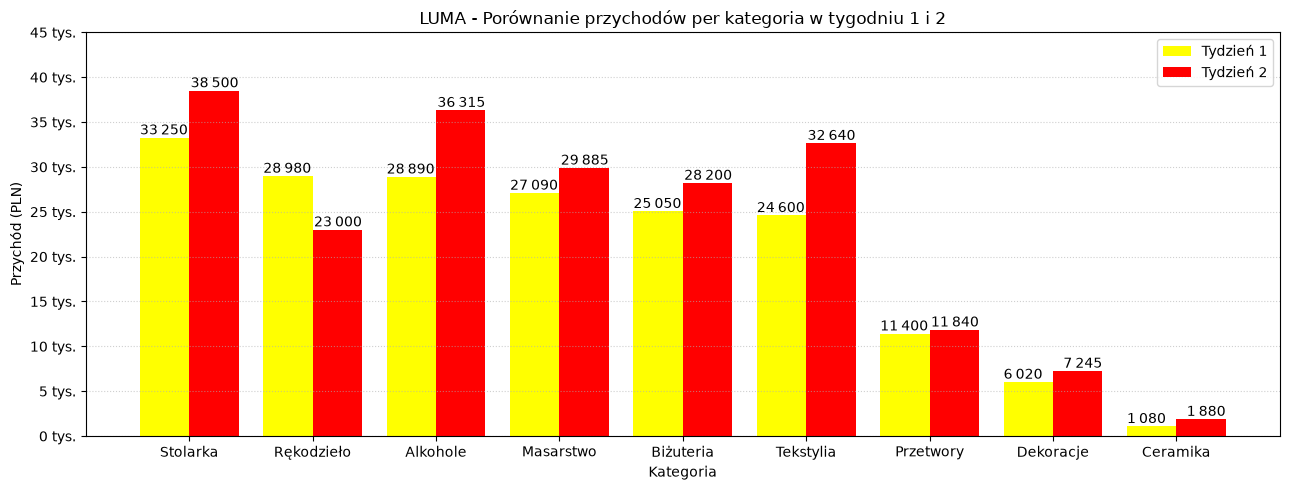

In [34]:
plt.figure(figsize=(13,5))
bars_1 = plt.bar(x_locs-bar_half, t1_revenue_total, width=bar_width, label="Tydzień 1", color="yellow")
bars_2 = plt.bar(x_locs+bar_half, t2_revenue_total, width=bar_width, label="Tydzień 2", color="red")
plt.xticks(x_locs, categories)
pad_axis()
for b in bars_1:
    x, y = b.get_x(), b.get_height()
    plt.text(x, y, format_sep(y), ha="left", va="bottom")
for b in bars_2:
    x, y = b.get_x() + b.get_width(), b.get_height()
    plt.text(x, y, format_sep(y), ha="right", va="bottom")
format_ytics_tys()
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.title("LUMA - Porównanie przychodów per kategoria w tygodniu 1 i 2")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.legend()
plt.tight_layout()
plt.show()

## Analiza i iwzualizacja danych - prezentacja zmian bezwzględnych

Przygotowanie różnic i procentowych zmian między tygodniami 1 i 2

In [35]:
order = CATEGORIES
t1_revenue_total = t1.set_index("category").loc[order]["revenue_pln"]
t2_revenue_total = t2.set_index("category").loc[order]["revenue_pln"]

base = t1_revenue_total
delta = t2_revenue_total - t1_revenue_total

pct = np.divide(
    delta,
    base,
    out=np.full_like(base, np.nan, dtype=float), 
    where=base != 0 
) * 100

t_delta = pd.DataFrame({
    "category": order,
    "t1_pln": t1_revenue_total.astype(int),
    "t2_pln": t2_revenue_total.astype(int),
    "delta_pln": delta.astype(int),
    "delta_pct": np.round(pct, 1)
}).reset_index(drop=True)
display(t_delta)

,category,t1_pln,t2_pln,delta_pln,delta_pct
0,Ceramika,1080,1880,800,74.1
1,Tekstylia,24600,32640,8040,32.7
2,Biżuteria,25050,28200,3150,12.6
3,Rękodzieło,28980,23000,-5980,-20.6
4,Przetwory,11400,11840,440,3.9
5,Dekoracje,6020,7245,1225,20.3
6,Stolarka,33250,38500,5250,15.8
7,Masarstwo,27090,29885,2795,10.3
8,Alkohole,28890,36315,7425,25.7


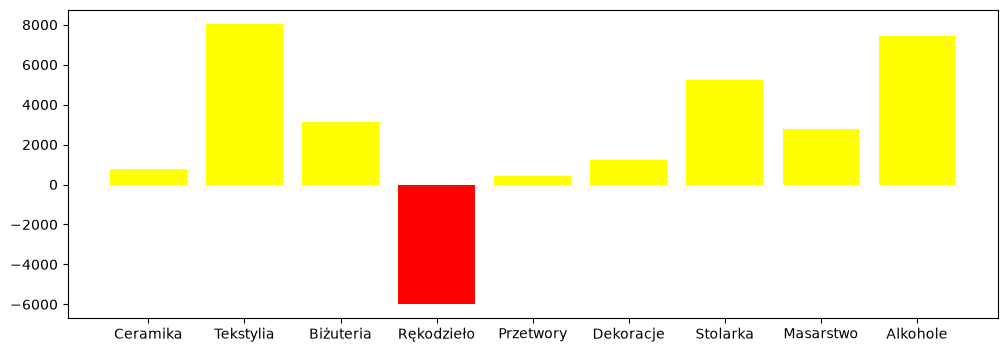

In [38]:
colors = ["yellow" if v >= 0 else "red" for v in t_delta['delta_pln']]
plt.figure(figsize=(12,4))
plt.bar(t_delta["category"], t_delta["delta_pln"], color=colors)
plt.show()

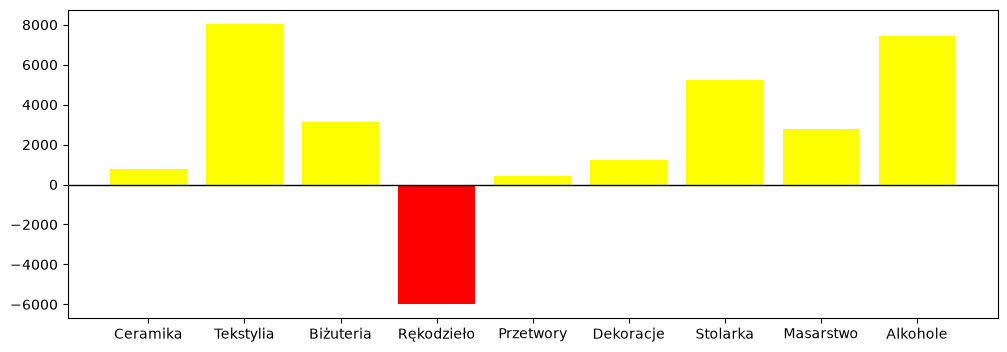

In [39]:
colors = ["yellow" if v >= 0 else "red" for v in t_delta['delta_pln']]
plt.figure(figsize=(12,4))
plt.bar(t_delta["category"], t_delta["delta_pln"], color=colors)
plt.axhline(0, color="black", linewidth=1)
plt.show()

In [40]:
def format_sep_signed(x: float) -> str:
    s = format_sep((abs(x)))
    return ("+" if x>=0 else "\u2212") + s

In [41]:
def pad_ylims(axes, factor=0.07):
    ymin, ymax = axes.get_ylim() # pobranie min i max dla y
    pad = (ymax - ymin) * factor
    plt.ylim(ymin - pad, ymax + pad) # nowa wartość y max

In [42]:
def label_bars(axes, bars, values, formatter=format_sep_signed, offset_factor=0.02):
    ymin, ymax = axes.get_ylim()
    offset = (ymax - ymin) * offset_factor
    for b, v in zip(bars, values):
        x = b.get_x() + b.get_width() / 2
        y = b.get_y() + b.get_height()
        label = formatter(v)
        va = "top" if v < 0 else "bottom"
        y_text = y-offset if v < 0 else y+offset
        axes.text(x, y_text, label, ha="center", va=va)

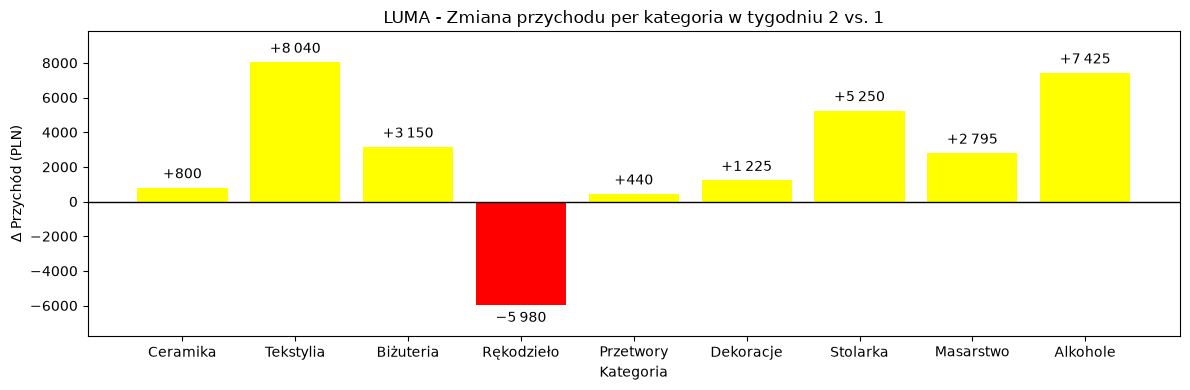

In [43]:
plt.figure(figsize=(12,4))
bars = plt.bar(t_delta["category"], t_delta["delta_pln"], color=colors)
pad_ylims(plt.gca())
label_bars(plt.gca(), bars, t_delta["delta_pln"])
plt.axhline(0, color="black", linewidth=1)
plt.title("LUMA - Zmiana przychodu per kategoria w tygodniu 2 vs. 1")
plt.xlabel("Kategoria")
plt.ylabel("\u2206 Przychód (PLN)")
plt.tight_layout()
plt.show()

## Analiza i wizualizacja danych - prezentacja zmian względnyh (procenowych)

In [44]:
t_delta["delta_pct_plot"] = np.nan_to_num(t_delta["delta_pct"], nan = 0.0)

In [46]:
def format_pct_signed(p: float) -> str:
    if np.isnan(p):
        return "n/n"
    if p == 0:
        return "0"
    s = format_sep(abs(p))
    return ("+" if p >= 0 else "\u2212") + s + " %"

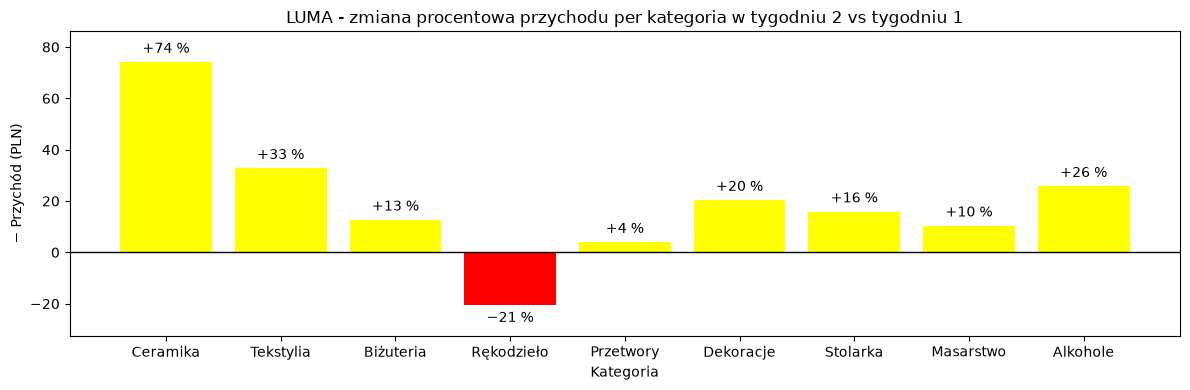

In [49]:
colors_pct = ["yellow" if p > 0 else "red" if p < 0 else "gray" for p in t_delta['delta_pct_plot']]
plt.figure(figsize=(12, 4))
bars = plt.bar(t_delta["category"], t_delta["delta_pct_plot"], color = colors_pct)
pad_ylims(plt.gca())
label_bars(plt.gca(), bars, t_delta["delta_pct_plot"], formatter = format_pct_signed)
plt.axhline(0, color="black", linewidth = 1)
plt.title("LUMA - zmiana procentowa przychodu per kategoria w tygodniu 2 vs tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("\u2212 Przychód (PLN)")
plt.tight_layout()
plt.show()

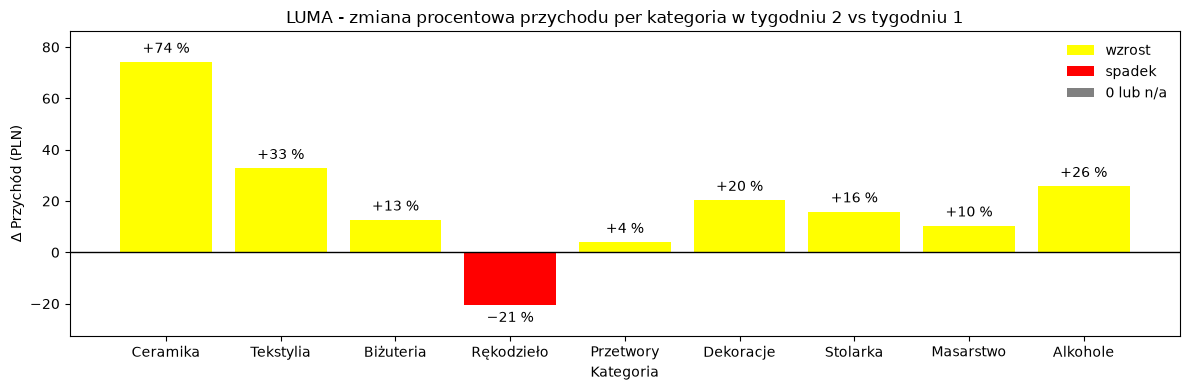

In [51]:
plt.figure(figsize= (12, 4))
bars = plt.bar(t_delta["category"], t_delta["delta_pct_plot"], color = colors_pct)
for b, p in zip(bars, t_delta["delta_pct_plot"]):
    if np.isnan(p) or p == 0:
        b.set_y(-3)
        b.set_height(6)
        b.set_color("gray")
pad_ylims(plt.gca())
label_bars(plt.gca(), bars, t_delta["delta_pct_plot"], formatter = format_pct_signed)
legends_patches = [
    Patch(facecolor="yellow", label="wzrost"),
    Patch(facecolor="red", label="spadek"),
    Patch(facecolor="gray", label="0 lub n/a")
]
plt.legend(handles=legends_patches, frameon=False)
plt.axhline(0, color="black", linewidth = 1)
plt.title("LUMA - zmiana procentowa przychodu per kategoria w tygodniu 2 vs tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("\u2206 Przychód (PLN)")
plt.tight_layout()
plt.show()